In [1]:
# ============================================
# RETAILPULSE - FEATURE ENGINEERING
# ============================================

import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries imported!")

# ============================================
# BULLETPROOF PATHS
# ============================================
current_dir = os.getcwd()
if os.path.basename(current_dir) == "notebooks":
    project_root = os.path.abspath(os.path.join(current_dir, ".."))
else:
    project_root = os.path.abspath(current_dir)

processed_dir = os.path.join(project_root, "data", "processed")

# ============================================
# LOAD CLEANED DATASETS
# ============================================
print("\n📂 Loading cleaned datasets...")

# Full dataset (for forecasting & inventory)
full_path = os.path.join(processed_dir, "cleaned_full.parquet")
df_full = pd.read_parquet(full_path)
df_full['InvoiceDate'] = pd.to_datetime(df_full['InvoiceDate'])
print(f"   ✅ Full Clean: {len(df_full):,} rows")

# Customer dataset (for segmentation & churn)
cust_path = os.path.join(processed_dir, "cleaned_customers.parquet")
df_cust = pd.read_parquet(cust_path)
df_cust['InvoiceDate'] = pd.to_datetime(df_cust['InvoiceDate'])
df_cust['Customer ID'] = df_cust['Customer ID'].astype(int)
print(f"   ✅ Customer Clean: {len(df_cust):,} rows, "
      f"{df_cust['Customer ID'].nunique():,} unique customers")

# Define the "current date" as the day after the last transaction
# This simulates "today" from the perspective of the dataset
snapshot_date = df_full['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"\n📅 Snapshot Date (simulated 'today'): {snapshot_date.date()}")
print("   (We use this as the reference point for Recency and Churn)")

✅ Libraries imported!

📂 Loading cleaned datasets...
   ✅ Full Clean: 1,007,913 rows
   ✅ Customer Clean: 779,425 rows, 5,878 unique customers

📅 Snapshot Date (simulated 'today'): 2011-12-10
   (We use this as the reference point for Recency and Churn)


In [2]:
# ============================================
# PART A: RFM FEATURE ENGINEERING
# ============================================

print("🔧 CALCULATING RFM FEATURES...")
print("=" * 60)

# Group by Customer ID and calculate R, F, M
rfm = df_cust.groupby('Customer ID').agg(
    # RECENCY: Days since last purchase
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    
    # FREQUENCY: Number of unique orders (invoices)
    Frequency=('Invoice', 'nunique'),
    
    # MONETARY: Total revenue spent
    Monetary=('Revenue', 'sum')
).reset_index()

print(f"✅ RFM calculated for {len(rfm):,} customers")
print()

# Show statistics
print("📊 RFM STATISTICS:")
print("-" * 50)
print(f"   RECENCY (days since last purchase):")
print(f"      Min: {rfm['Recency'].min()} days (bought yesterday!)")
print(f"      Max: {rfm['Recency'].max()} days (hasn't bought in ~2 years)")
print(f"      Median: {rfm['Recency'].median():.0f} days")
print()
print(f"   FREQUENCY (number of orders):")
print(f"      Min: {rfm['Frequency'].min()} order(s)")
print(f"      Max: {rfm['Frequency'].max()} orders")
print(f"      Median: {rfm['Frequency'].median():.0f} orders")
print()
print(f"   MONETARY (total spent £):")
print(f"      Min: £{rfm['Monetary'].min():.2f}")
print(f"      Max: £{rfm['Monetary'].max():,.2f}")
print(f"      Median: £{rfm['Monetary'].median():.2f}")
print()

# Show top 5 customers by each metric
print("🏆 TOP 5 MOST RECENT CUSTOMERS:")
for _, row in rfm.nsmallest(5, 'Recency').iterrows():
    print(f"   Customer {row['Customer ID']}: {row['Recency']} days ago")

print("\n🏆 TOP 5 MOST FREQUENT CUSTOMERS:")
for _, row in rfm.nlargest(5, 'Frequency').iterrows():
    print(f"   Customer {row['Customer ID']}: {row['Frequency']} orders")

print("\n🏆 TOP 5 HIGHEST SPENDERS:")
for _, row in rfm.nlargest(5, 'Monetary').iterrows():
    print(f"   Customer {row['Customer ID']}: £{row['Monetary']:,.2f}")

🔧 CALCULATING RFM FEATURES...
✅ RFM calculated for 5,878 customers

📊 RFM STATISTICS:
--------------------------------------------------
   RECENCY (days since last purchase):
      Min: 1 days (bought yesterday!)
      Max: 739 days (hasn't bought in ~2 years)
      Median: 96 days

   FREQUENCY (number of orders):
      Min: 1 order(s)
      Max: 398 orders
      Median: 3 orders

   MONETARY (total spent £):
      Min: £2.95
      Max: £237,642.04
      Median: £753.68

🏆 TOP 5 MOST RECENT CUSTOMERS:
   Customer 12423.0: 1.0 days ago
   Customer 12433.0: 1.0 days ago
   Customer 12518.0: 1.0 days ago
   Customer 12526.0: 1.0 days ago
   Customer 12662.0: 1.0 days ago

🏆 TOP 5 MOST FREQUENT CUSTOMERS:
   Customer 14911.0: 398.0 orders
   Customer 12748.0: 336.0 orders
   Customer 17841.0: 211.0 orders
   Customer 15311.0: 208.0 orders
   Customer 13089.0: 203.0 orders

🏆 TOP 5 HIGHEST SPENDERS:
   Customer 14911.0: £237,642.04
   Customer 14646.0: £167,806.52
   Customer 14156.0: £12

In [3]:
# ============================================
# RFM SCORING (1-5 scale)
# ============================================

print("🔧 CREATING RFM SCORES (1-5 scale)...")
print("-" * 50)

# We use quantile-based scoring (each score represents ~20% of customers)
# For Recency: LOWER is BETTER (recent = good), so we reverse the scoring
# For Frequency & Monetary: HIGHER is BETTER

# Recency Score (1 = least recent, 5 = most recent)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency Score (1 = least frequent, 5 = most frequent)
# Use rank method to handle ties
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Monetary Score (1 = lowest spender, 5 = highest spender)
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Combined RFM Score (e.g., 555 = best customer, 111 = worst)
rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

print(f"✅ RFM scores created!")
print()

# Show score distribution
print("📊 RFM SCORE DISTRIBUTION:")
print(f"   R_Score (Recency):")
for score in range(1, 6):
    count = (rfm['R_Score'] == score).sum()
    print(f"      Score {score}: {count:,} customers ({count/len(rfm)*100:.1f}%)")

print(f"\n   F_Score (Frequency):")
for score in range(1, 6):
    count = (rfm['F_Score'] == score).sum()
    print(f"      Score {score}: {count:,} customers ({count/len(rfm)*100:.1f}%)")

print(f"\n   M_Score (Monetary):")
for score in range(1, 6):
    count = (rfm['M_Score'] == score).sum()
    print(f"      Score {score}: {count:,} customers ({count/len(rfm)*100:.1f}%)")

print(f"\n   Sample RFM Scores:")
for _, row in rfm.head(5).iterrows():
    print(f"      Customer {row['Customer ID']}: RFM = {row['RFM_Score']} "
          f"(R={row['Recency']}d, F={row['Frequency']}, M=£{row['Monetary']:.0f})")

🔧 CREATING RFM SCORES (1-5 scale)...
--------------------------------------------------
✅ RFM scores created!

📊 RFM SCORE DISTRIBUTION:
   R_Score (Recency):
      Score 1: 1,175 customers (20.0%)
      Score 2: 1,172 customers (19.9%)
      Score 3: 1,167 customers (19.9%)
      Score 4: 1,176 customers (20.0%)
      Score 5: 1,188 customers (20.2%)

   F_Score (Frequency):
      Score 1: 1,176 customers (20.0%)
      Score 2: 1,175 customers (20.0%)
      Score 3: 1,176 customers (20.0%)
      Score 4: 1,175 customers (20.0%)
      Score 5: 1,176 customers (20.0%)

   M_Score (Monetary):
      Score 1: 1,176 customers (20.0%)
      Score 2: 1,175 customers (20.0%)
      Score 3: 1,176 customers (20.0%)
      Score 4: 1,175 customers (20.0%)
      Score 5: 1,176 customers (20.0%)

   Sample RFM Scores:
      Customer 12346: RFM = 252 (R=326d, F=12, M=£402)
      Customer 12347: RFM = 545 (R=2d, F=8, M=£4520)
      Customer 12348: RFM = 343 (R=75d, F=5, M=£810)
      Customer 12349: R

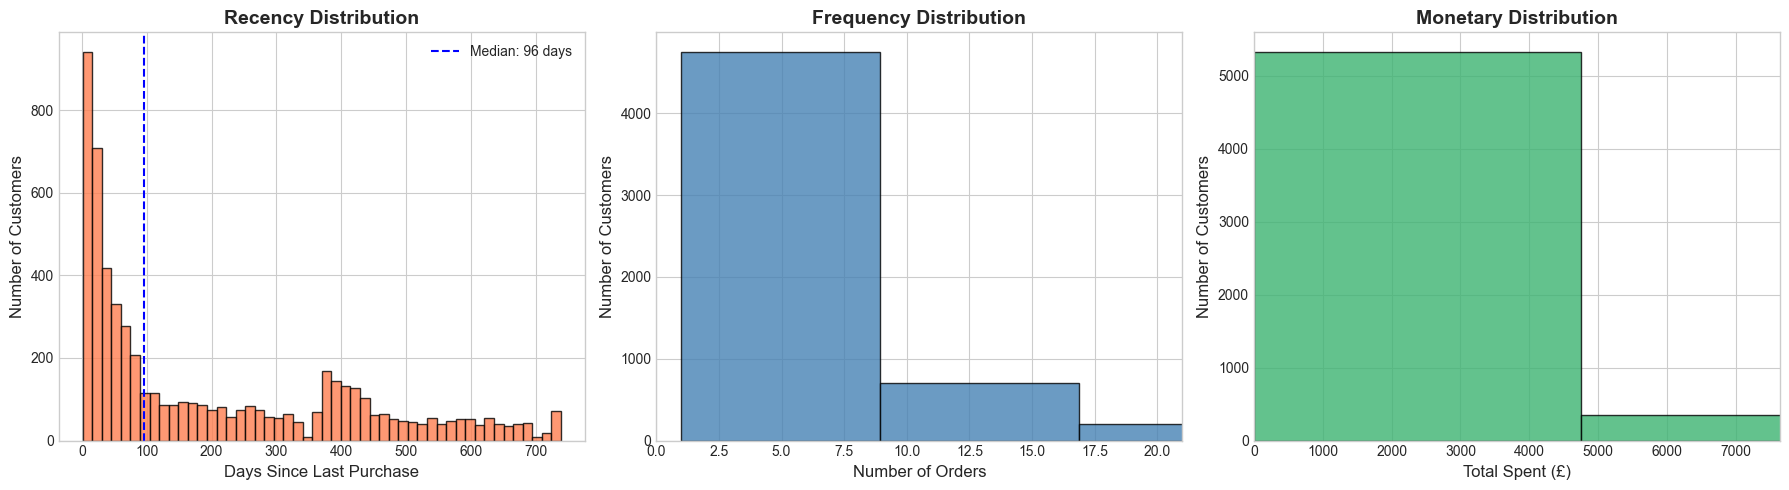

💡 INSIGHT: Most customers have low frequency and low monetary value.
   A small number of VIP customers drive most of the revenue.


In [4]:
# ============================================
# RFM VISUALIZATION
# ============================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Recency Distribution
axes[0].hist(rfm['Recency'], bins=50, color='coral', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Days Since Last Purchase', fontsize=12)
axes[0].set_ylabel('Number of Customers', fontsize=12)
axes[0].set_title('Recency Distribution', fontsize=14, fontweight='bold')
axes[0].axvline(x=rfm['Recency'].median(), color='blue', linestyle='--', 
                label=f"Median: {rfm['Recency'].median():.0f} days")
axes[0].legend()

# Frequency Distribution
axes[1].hist(rfm['Frequency'], bins=50, color='steelblue', edgecolor='black', alpha=0.8)
axes[1].set_xlabel('Number of Orders', fontsize=12)
axes[1].set_ylabel('Number of Customers', fontsize=12)
axes[1].set_title('Frequency Distribution', fontsize=14, fontweight='bold')
axes[1].set_xlim(0, rfm['Frequency'].quantile(0.95))  # Zoom in

# Monetary Distribution
axes[2].hist(rfm['Monetary'], bins=50, color='mediumseagreen', edgecolor='black', alpha=0.8)
axes[2].set_xlabel('Total Spent (£)', fontsize=12)
axes[2].set_ylabel('Number of Customers', fontsize=12)
axes[2].set_title('Monetary Distribution', fontsize=14, fontweight='bold')
axes[2].set_xlim(0, rfm['Monetary'].quantile(0.95))  # Zoom in

plt.tight_layout()
os.makedirs(os.path.join(project_root, "reports", "figures"), exist_ok=True)
plt.savefig(os.path.join(project_root, "reports", "figures", "rfm_distributions.png"), 
            dpi=150, bbox_inches='tight')
plt.show()

print("💡 INSIGHT: Most customers have low frequency and low monetary value.")
print("   A small number of VIP customers drive most of the revenue.")

In [5]:
# ============================================
# ADDITIONAL CUSTOMER BEHAVIORAL FEATURES
# ============================================

print("🔧 CREATING BEHAVIORAL FEATURES...")
print("=" * 60)

# Calculate additional features per customer
customer_features = df_cust.groupby('Customer ID').agg(
    # Basic RFM (already calculated, but let's add more)
    First_Purchase=('InvoiceDate', 'min'),
    Last_Purchase=('InvoiceDate', 'max'),
    Total_Orders=('Invoice', 'nunique'),
    Total_Items=('Quantity', 'sum'),
    Total_Revenue=('Revenue', 'sum'),
    
    # Average metrics per order
    Avg_Order_Value=('Revenue', lambda x: x.groupby(df_cust.loc[x.index, 'Invoice']).sum().mean()),
    Avg_Items_Per_Order=('Quantity', 'mean'),
    Avg_Price_Per_Item=('Price', 'mean'),
    
    # Purchase consistency
    Unique_Products=('StockCode', 'nunique'),
    Unique_Months=('InvoiceDate', lambda x: x.dt.to_period('M').nunique()),
    
    # Country (take the most common one)
    Primary_Country=('Country', lambda x: x.mode()[0])
).reset_index()

# Calculate Customer Lifespan (days between first and last purchase)
customer_features['Lifespan_Days'] = (customer_features['Last_Purchase'] - 
                                       customer_features['First_Purchase']).dt.days

# Purchase Rate (orders per month of lifespan)
customer_features['Purchase_Rate_Per_Month'] = np.where(
    customer_features['Lifespan_Days'] > 0,
    customer_features['Total_Orders'] / (customer_features['Lifespan_Days'] / 30),
    customer_features['Total_Orders']  # If only 1 day, use total orders
)

# Revenue Per Month
customer_features['Revenue_Per_Month'] = np.where(
    customer_features['Lifespan_Days'] > 0,
    customer_features['Total_Revenue'] / (customer_features['Lifespan_Days'] / 30),
    customer_features['Total_Revenue']
)

# Product Diversity (unique products / total orders)
customer_features['Product_Diversity'] = (customer_features['Unique_Products'] / 
                                           customer_features['Total_Orders']).round(2)

print(f"✅ Created {len(customer_features.columns) - 1} features for {len(customer_features):,} customers")
print()

print("📊 NEW FEATURE STATISTICS:")
print("-" * 60)
features_to_show = ['Lifespan_Days', 'Purchase_Rate_Per_Month', 'Revenue_Per_Month', 
                    'Avg_Order_Value', 'Product_Diversity', 'Unique_Products']
for feat in features_to_show:
    print(f"   {feat:30s} | Mean: {customer_features[feat].mean():>10.2f} | "
          f"Median: {customer_features[feat].median():>10.2f}")

🔧 CREATING BEHAVIORAL FEATURES...
✅ Created 15 features for 5,878 customers

📊 NEW FEATURE STATISTICS:
------------------------------------------------------------
   Lifespan_Days                  | Mean:     273.02 | Median:     220.50
   Purchase_Rate_Per_Month        | Mean:       1.06 | Median:       0.82
   Revenue_Per_Month              | Mean:     294.28 | Median:     157.09
   Avg_Order_Value                | Mean:     293.99 | Median:     243.42
   Product_Diversity              | Mean:      17.68 | Median:      13.88
   Unique_Products                | Mean:      81.99 | Median:      45.00


🔧 CREATING CHURN LABELS...
   Snapshot Date:    2011-12-10
   Churn Cutoff:     2011-09-11
   Threshold:        90 days of inactivity

📊 CHURN STATISTICS:
   Total Customers:  5,878
   Active (bought in last 90 days):  2,889 (49.1%)
   Churned (inactive 90+ days):      2,989 (50.9%)

📊 CHURN RATE BY RECENCY SCORE:
   R_Score 1 (Oldest      ): 100.0% churned (1175/1175)
   R_Score 2 (Old         ): 100.0% churned (1172/1172)
   R_Score 3 (Moderate    ):  55.0% churned (642/1167)
   R_Score 4 (Recent      ):   0.0% churned (0/1176)
   R_Score 5 (Most Recent ):   0.0% churned (0/1188)


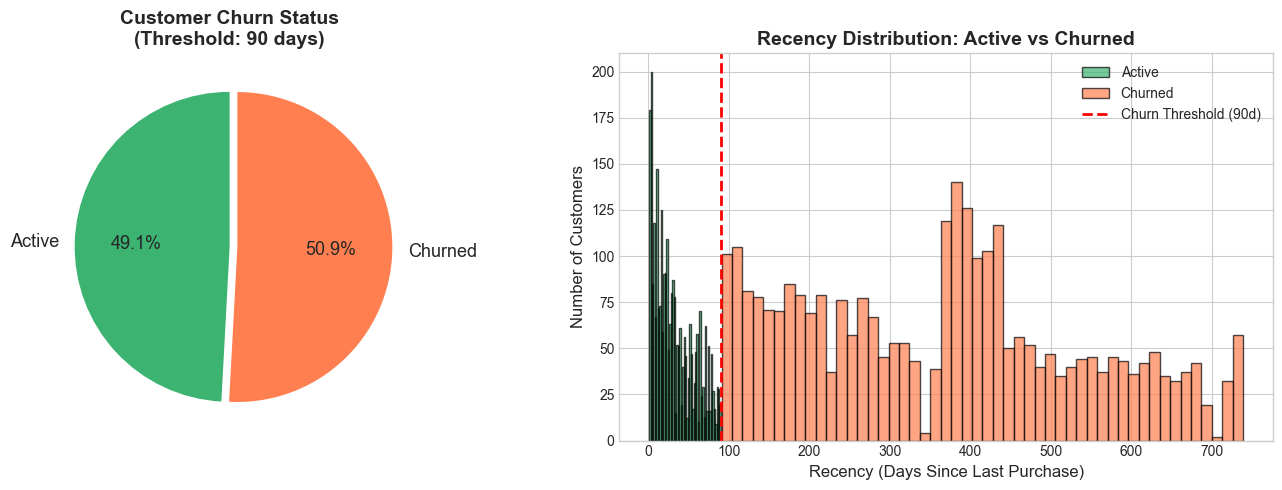


💡 INSIGHT: ~51% of customers are churned.
   This gives us a reasonably balanced dataset for churn prediction.


In [6]:
# ============================================
# CHURN LABEL CREATION
# ============================================

print("🔧 CREATING CHURN LABELS...")
print("=" * 60)

# Define churn threshold
CHURN_THRESHOLD_DAYS = 90
churn_cutoff_date = snapshot_date - pd.Timedelta(days=CHURN_THRESHOLD_DAYS)

print(f"   Snapshot Date:    {snapshot_date.date()}")
print(f"   Churn Cutoff:     {churn_cutoff_date.date()}")
print(f"   Threshold:        {CHURN_THRESHOLD_DAYS} days of inactivity")
print()

# A customer is churned if their last purchase was BEFORE the cutoff date
rfm['Is_Churned'] = (rfm['Recency'] > CHURN_THRESHOLD_DAYS).astype(int)

# Churn statistics
total_customers = len(rfm)
churned = rfm['Is_Churned'].sum()
active = total_customers - churned

print(f"📊 CHURN STATISTICS:")
print(f"   Total Customers:  {total_customers:,}")
print(f"   Active (bought in last 90 days):  {active:,} ({active/total_customers*100:.1f}%)")
print(f"   Churned (inactive 90+ days):      {churned:,} ({churned/total_customers*100:.1f}%)")
print()

# Churn by RFM segment
print("📊 CHURN RATE BY RECENCY SCORE:")
for score in range(1, 6):
    subset = rfm[rfm['R_Score'] == score]
    churn_rate = subset['Is_Churned'].mean() * 100
    label = {5: 'Most Recent', 4: 'Recent', 3: 'Moderate', 2: 'Old', 1: 'Oldest'}[score]
    print(f"   R_Score {score} ({label:12s}): {churn_rate:>5.1f}% churned "
          f"({subset['Is_Churned'].sum()}/{len(subset)})")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LEFT: Churn pie chart
labels = ['Active', 'Churned']
sizes = [active, churned]
colors = ['mediumseagreen', 'coral']
explode = (0, 0.05)

axes[0].pie(sizes, explode=explode, labels=labels, colors=colors, 
            autopct='%1.1f%%', startangle=90, textprops={'fontsize': 13})
axes[0].set_title(f'Customer Churn Status\n(Threshold: {CHURN_THRESHOLD_DAYS} days)', 
                  fontsize=14, fontweight='bold')

# RIGHT: Recency distribution by churn status
axes[1].hist(rfm[rfm['Is_Churned'] == 0]['Recency'], bins=50, 
             color='mediumseagreen', alpha=0.7, label='Active', edgecolor='black')
axes[1].hist(rfm[rfm['Is_Churned'] == 1]['Recency'], bins=50, 
             color='coral', alpha=0.7, label='Churned', edgecolor='black')
axes[1].axvline(x=CHURN_THRESHOLD_DAYS, color='red', linestyle='--', linewidth=2, 
                label=f'Churn Threshold ({CHURN_THRESHOLD_DAYS}d)')
axes[1].set_xlabel('Recency (Days Since Last Purchase)', fontsize=12)
axes[1].set_ylabel('Number of Customers', fontsize=12)
axes[1].set_title('Recency Distribution: Active vs Churned', fontsize=14, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(project_root, "reports", "figures", "churn_analysis.png"), 
            dpi=150, bbox_inches='tight')
plt.show()

print(f"\n💡 INSIGHT: ~{churned/total_customers*100:.0f}% of customers are churned.")
print("   This gives us a reasonably balanced dataset for churn prediction.")

In [7]:
# ============================================
# COMBINE ALL CUSTOMER FEATURES
# ============================================

print("🔧 COMBINING ALL CUSTOMER FEATURES...")
print("=" * 60)

# Merge RFM scores with behavioral features
# First, add Recency, Frequency, Monetary from rfm to customer_features
customer_final = customer_features.merge(
    rfm[['Customer ID', 'Recency', 'Frequency', 'Monetary', 
         'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'Is_Churned']],
    on='Customer ID',
    how='inner'
)

# Drop date columns (models need numbers, not dates)
customer_final = customer_final.drop(columns=['First_Purchase', 'Last_Purchase'], errors='ignore')

print(f"✅ Final customer feature matrix:")
print(f"   Rows: {len(customer_final):,} customers")
print(f"   Columns: {len(customer_final.columns)} features")
print()

print("📋 ALL FEATURES:")
for i, col in enumerate(customer_final.columns, 1):
    dtype = customer_final[col].dtype
    print(f"   {i:>2}. {col:35s} ({dtype})")

# Save customer features
cust_feat_path = os.path.join(processed_dir, "customer_features.parquet")
customer_final.to_parquet(cust_feat_path, index=False, engine='pyarrow')
print(f"\n💾 Saved customer features to: {cust_feat_path}")
print(f"   Size: {os.path.getsize(cust_feat_path)/(1024*1024):.1f} MB")

# Also save as CSV for easy viewing
cust_feat_csv = os.path.join(processed_dir, "customer_features.csv")
customer_final.to_csv(cust_feat_csv, index=False)
print(f"💾 Saved customer features CSV to: {cust_feat_csv}")

🔧 COMBINING ALL CUSTOMER FEATURES...
✅ Final customer feature matrix:
   Rows: 5,878 customers
   Columns: 22 features

📋 ALL FEATURES:
    1. Customer ID                         (int32)
    2. Total_Orders                        (int64)
    3. Total_Items                         (float64)
    4. Total_Revenue                       (float64)
    5. Avg_Order_Value                     (float64)
    6. Avg_Items_Per_Order                 (float64)
    7. Avg_Price_Per_Item                  (float64)
    8. Unique_Products                     (int64)
    9. Unique_Months                       (int64)
   10. Primary_Country                     (object)
   11. Lifespan_Days                       (int64)
   12. Purchase_Rate_Per_Month             (float64)
   13. Revenue_Per_Month                   (float64)
   14. Product_Diversity                   (float64)
   15. Recency                             (int64)
   16. Frequency                           (int64)
   17. Monetary                

In [8]:
# ============================================
# PART B: TIME-SERIES FEATURE ENGINEERING
# ============================================

print("\n🔧 CREATING TIME-SERIES FEATURES...")
print("=" * 60)

# For forecasting, we need data aggregated by time period
# Let's create DAILY sales data first, then add features

# Daily aggregation from full dataset
daily_sales = df_full.groupby(df_full['InvoiceDate'].dt.date).agg(
    Daily_Revenue=('Revenue', 'sum'),
    Daily_Quantity=('Quantity', 'sum'),
    Daily_Orders=('Invoice', 'nunique'),
    Daily_Customers=('Customer ID', 'nunique'),  # Some will be NaN, that's OK
    Avg_Price=('Price', 'mean')
).reset_index()

daily_sales.rename(columns={'InvoiceDate': 'Date'}, inplace=True)
daily_sales['Date'] = pd.to_datetime(daily_sales['Date'])
daily_sales = daily_sales.sort_values('Date').reset_index(drop=True)

# Fill NaN in Daily_Customers with 0
daily_sales['Daily_Customers'] = daily_sales['Daily_Customers'].fillna(0)

print(f"✅ Daily sales data created:")
print(f"   Date range: {daily_sales['Date'].min().date()} to {daily_sales['Date'].max().date()}")
print(f"   Total days: {len(daily_sales)}")
print(f"   Avg daily revenue: £{daily_sales['Daily_Revenue'].mean():,.2f}")
print()

# Show first and last 5 days
print("📊 FIRST 5 DAYS:")
print(daily_sales.head().to_string(index=False))
print("\n📊 LAST 5 DAYS:")
print(daily_sales.tail().to_string(index=False))


🔧 CREATING TIME-SERIES FEATURES...
✅ Daily sales data created:
   Date range: 2009-12-01 to 2011-12-09
   Total days: 604
   Avg daily revenue: £23,373.28

📊 FIRST 5 DAYS:
      Date  Daily_Revenue  Daily_Quantity  Daily_Orders  Daily_Customers  Avg_Price
2009-12-01      42916.085         19361.0           119               91   3.534550
2009-12-02      41597.405         19021.5           115               94   3.290408
2009-12-03      42148.750         19864.5           124              106   3.141235
2009-12-04      32791.185         16327.5            89               76   3.098814
2009-12-05       8968.755          4135.5            30               26   3.340275

📊 LAST 5 DAYS:
      Date  Daily_Revenue  Daily_Quantity  Daily_Orders  Daily_Customers  Avg_Price
2011-12-05      63514.725         31523.0           127              105   3.071164
2011-12-06      40440.055         22435.0           115              103   2.599380
2011-12-07      41659.065         23556.5           106

In [9]:
# ============================================
# TIME-BASED FEATURES
# ============================================

print("\n🔧 CREATING TIME-BASED FEATURES...")

# Extract time components
daily_sales['Year'] = daily_sales['Date'].dt.year
daily_sales['Month'] = daily_sales['Date'].dt.month
daily_sales['Day'] = daily_sales['Date'].dt.day
daily_sales['DayOfWeek'] = daily_sales['Date'].dt.dayofweek  # 0=Mon, 6=Sun
daily_sales['WeekOfYear'] = daily_sales['Date'].dt.isocalendar().week.astype(int)
daily_sales['Quarter'] = daily_sales['Date'].dt.quarter
daily_sales['DayOfYear'] = daily_sales['Date'].dt.dayofyear
daily_sales['Is_Weekend'] = (daily_sales['DayOfWeek'] >= 5).astype(int)

# Seasonal indicators (useful for capturing Christmas, summer, etc.)
daily_sales['Is_Q4'] = (daily_sales['Quarter'] == 4).astype(int)  # Oct-Dec
daily_sales['Is_December'] = (daily_sales['Month'] == 12).astype(int)
daily_sales['Is_Nov_Dec'] = (daily_sales['Month'].isin([11, 12])).astype(int)

# Cyclical encoding (helps models understand that Dec → Jan is a small jump)
# Think of months as a clock: December (12) is close to January (1), not far!
daily_sales['Month_Sin'] = np.sin(2 * np.pi * daily_sales['Month'] / 12)
daily_sales['Month_Cos'] = np.cos(2 * np.pi * daily_sales['Month'] / 12)
daily_sales['DayOfWeek_Sin'] = np.sin(2 * np.pi * daily_sales['DayOfWeek'] / 7)
daily_sales['DayOfWeek_Cos'] = np.cos(2 * np.pi * daily_sales['DayOfWeek'] / 7)

print(f"✅ Created {12} time-based features")
print(f"   Features: Year, Month, Day, DayOfWeek, WeekOfYear, Quarter,")
print(f"             DayOfYear, Is_Weekend, Is_Q4, Is_December, Is_Nov_Dec,")
print(f"             Month_Sin, Month_Cos, DayOfWeek_Sin, DayOfWeek_Cos")


🔧 CREATING TIME-BASED FEATURES...
✅ Created 12 time-based features
   Features: Year, Month, Day, DayOfWeek, WeekOfYear, Quarter,
             DayOfYear, Is_Weekend, Is_Q4, Is_December, Is_Nov_Dec,
             Month_Sin, Month_Cos, DayOfWeek_Sin, DayOfWeek_Cos


In [10]:
# ============================================
# LAG FEATURES
# ============================================

print("\n🔧 CREATING LAG FEATURES...")

# What is a lag? It's the value from N days ago.
# Lag-1 = yesterday's sales
# Lag-7 = same day last week
# Lag-30 = same day last month

lag_periods = [1, 2, 3, 7, 14, 21, 28, 30]

for lag in lag_periods:
    daily_sales[f'Revenue_Lag_{lag}'] = daily_sales['Daily_Revenue'].shift(lag)
    daily_sales[f'Quantity_Lag_{lag}'] = daily_sales['Daily_Quantity'].shift(lag)

print(f"✅ Created {len(lag_periods) * 2} lag features")
print(f"   Revenue lags: {lag_periods}")
print(f"   Quantity lags: {lag_periods}")
print()
print("   Example: Revenue_Lag_7 = revenue from 7 days ago")
print("   This helps the model learn weekly patterns!")


🔧 CREATING LAG FEATURES...
✅ Created 16 lag features
   Revenue lags: [1, 2, 3, 7, 14, 21, 28, 30]
   Quantity lags: [1, 2, 3, 7, 14, 21, 28, 30]

   Example: Revenue_Lag_7 = revenue from 7 days ago
   This helps the model learn weekly patterns!


In [11]:
# ============================================
# ROLLING STATISTICS (Moving Averages)
# ============================================

print("\n🔧 CREATING ROLLING STATISTICS...")

# Rolling windows: 7 days (weekly), 14 days (bi-weekly), 30 days (monthly)
rolling_windows = [7, 14, 30]

for window in rolling_windows:
    # Rolling Mean (average over last N days)
    daily_sales[f'Revenue_Rolling_Mean_{window}'] = (
        daily_sales['Daily_Revenue'].rolling(window=window, min_periods=1).mean()
    )
    
    # Rolling Std (volatility over last N days)
    daily_sales[f'Revenue_Rolling_Std_{window}'] = (
        daily_sales['Daily_Revenue'].rolling(window=window, min_periods=1).std()
    )
    
    # Rolling Min & Max
    daily_sales[f'Revenue_Rolling_Min_{window}'] = (
        daily_sales['Daily_Revenue'].rolling(window=window, min_periods=1).min()
    )
    daily_sales[f'Revenue_Rolling_Max_{window}'] = (
        daily_sales['Daily_Revenue'].rolling(window=window, min_periods=1).max()
    )

print(f"✅ Created {len(rolling_windows) * 4} rolling features")
print(f"   Windows: {rolling_windows} days")
print(f"   Statistics: Mean, Std, Min, Max")
print()
print("   Example: Revenue_Rolling_Mean_7 = average revenue over the last 7 days")
print("   This smooths out daily noise and shows the trend!")


🔧 CREATING ROLLING STATISTICS...
✅ Created 12 rolling features
   Windows: [7, 14, 30] days
   Statistics: Mean, Std, Min, Max

   Example: Revenue_Rolling_Mean_7 = average revenue over the last 7 days
   This smooths out daily noise and shows the trend!


In [12]:
# ============================================
# DIFFERENCE FEATURES (Rate of Change)
# ============================================

print("\n🔧 CREATING DIFFERENCE FEATURES...")

# Difference = today's value minus yesterday's value
# This tells the model whether sales are going UP or DOWN

daily_sales['Revenue_Diff_1'] = daily_sales['Daily_Revenue'].diff(1)
daily_sales['Revenue_Diff_7'] = daily_sales['Daily_Revenue'].diff(7)
daily_sales['Quantity_Diff_1'] = daily_sales['Daily_Quantity'].diff(1)
daily_sales['Quantity_Diff_7'] = daily_sales['Daily_Quantity'].diff(7)

# Percentage change
daily_sales['Revenue_Pct_Change_1'] = daily_sales['Daily_Revenue'].pct_change(1)
daily_sales['Revenue_Pct_Change_7'] = daily_sales['Daily_Revenue'].pct_change(7)

print(f"✅ Created 6 difference features")
print(f"   Revenue_Diff_1: Change from yesterday")
print(f"   Revenue_Diff_7: Change from last week")
print(f"   Revenue_Pct_Change_1: % change from yesterday")
print(f"   Revenue_Pct_Change_7: % change from last week")


🔧 CREATING DIFFERENCE FEATURES...
✅ Created 6 difference features
   Revenue_Diff_1: Change from yesterday
   Revenue_Diff_7: Change from last week
   Revenue_Pct_Change_1: % change from yesterday
   Revenue_Pct_Change_7: % change from last week


In [13]:
# ============================================
# CLEAN UP TIME-SERIES FEATURES
# ============================================

print("\n🔧 CLEANING UP TIME-SERIES FEATURES...")
print("=" * 60)

# Lag and rolling features create NaN values at the beginning
# (e.g., Lag-30 has no value for the first 30 days)
nan_before = daily_sales.isnull().sum().sum()
print(f"   NaN values before cleanup: {nan_before:,}")

# Drop rows with NaN (first ~30 days, which is a small fraction)
daily_sales = daily_sales.dropna().reset_index(drop=True)
nan_after = daily_sales.isnull().sum().sum()
print(f"   NaN values after cleanup: {nan_after:,}")
print(f"   Rows remaining: {len(daily_sales)} (dropped ~30 days)")
print()

# Replace any remaining inf values
daily_sales = daily_sales.replace([np.inf, -np.inf], 0)

# Final feature count
feature_cols = [c for c in daily_sales.columns if c not in ['Date']]
print(f"📊 FINAL TIME-SERIES DATASET:")
print(f"   Rows: {len(daily_sales)} days")
print(f"   Total Columns: {len(daily_sales.columns)}")
print(f"   Feature Columns: {len(feature_cols)}")
print(f"   Target Column: Daily_Revenue (what we want to predict)")


🔧 CLEANING UP TIME-SERIES FEATURES...
   NaN values before cleanup: 239
   NaN values after cleanup: 0
   Rows remaining: 574 (dropped ~30 days)

📊 FINAL TIME-SERIES DATASET:
   Rows: 574 days
   Total Columns: 55
   Feature Columns: 54
   Target Column: Daily_Revenue (what we want to predict)


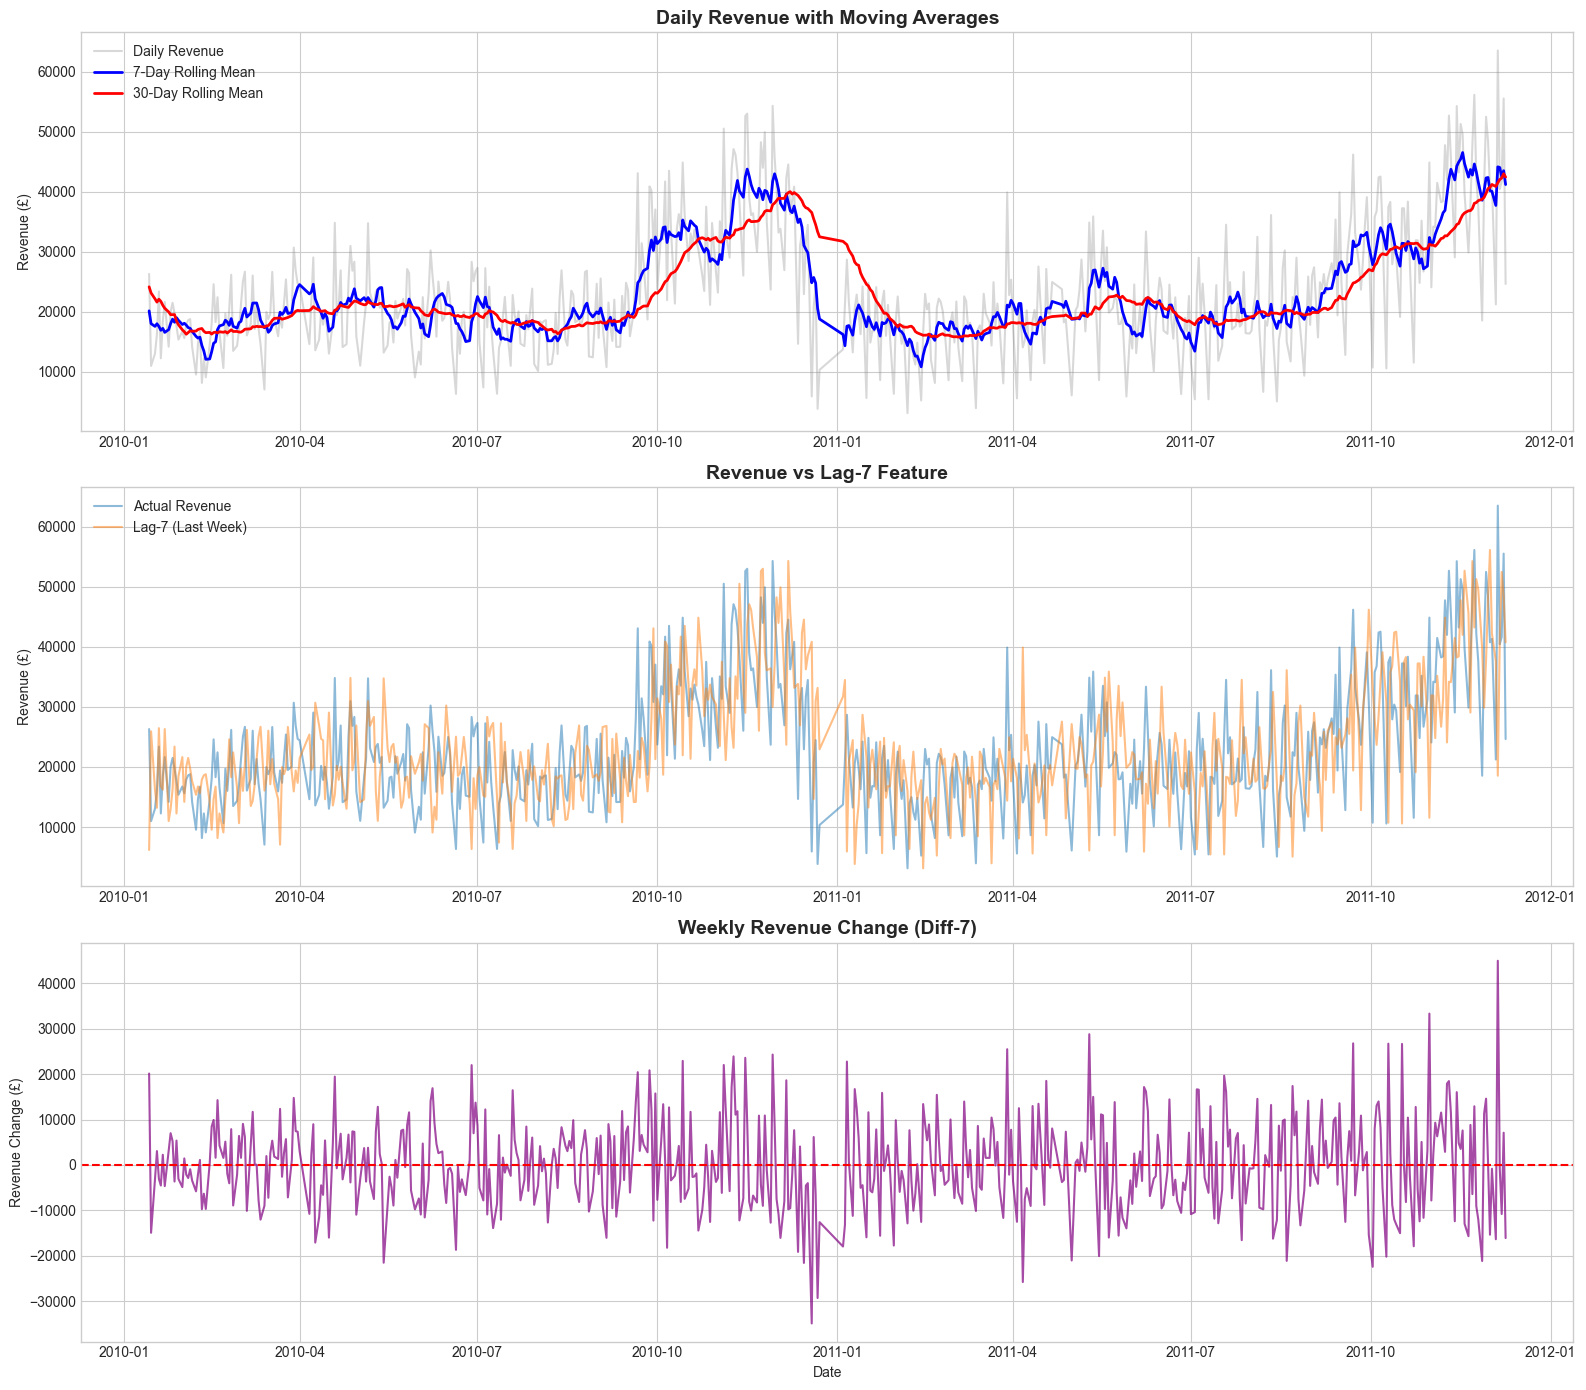

In [14]:
# ============================================
# VISUALIZE KEY TIME-SERIES FEATURES
# ============================================

fig, axes = plt.subplots(3, 1, figsize=(16, 14))

# TOP: Daily Revenue with Rolling Average
axes[0].plot(daily_sales['Date'], daily_sales['Daily_Revenue'], 
             alpha=0.3, color='gray', label='Daily Revenue')
axes[0].plot(daily_sales['Date'], daily_sales['Revenue_Rolling_Mean_7'], 
             color='blue', linewidth=2, label='7-Day Rolling Mean')
axes[0].plot(daily_sales['Date'], daily_sales['Revenue_Rolling_Mean_30'], 
             color='red', linewidth=2, label='30-Day Rolling Mean')
axes[0].set_title('Daily Revenue with Moving Averages', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Revenue (£)')
axes[0].legend()

# MIDDLE: Lag Features
axes[1].plot(daily_sales['Date'], daily_sales['Daily_Revenue'], 
             alpha=0.5, label='Actual Revenue')
axes[1].plot(daily_sales['Date'], daily_sales['Revenue_Lag_7'], 
             alpha=0.5, label='Lag-7 (Last Week)')
axes[1].set_title('Revenue vs Lag-7 Feature', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Revenue (£)')
axes[1].legend()

# BOTTOM: Rate of Change
axes[2].plot(daily_sales['Date'], daily_sales['Revenue_Diff_7'], 
             color='purple', alpha=0.7)
axes[2].axhline(y=0, color='red', linestyle='--')
axes[2].set_title('Weekly Revenue Change (Diff-7)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Revenue Change (£)')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.savefig(os.path.join(project_root, "reports", "figures", "timeseries_features.png"), 
            dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ============================================
# SAVE ALL ENGINEERED FEATURES
# ============================================

print("\n💾 SAVING ALL ENGINEERED FEATURES...")
print("=" * 60)

# Save daily time-series features
ts_parquet = os.path.join(processed_dir, "daily_timeseries_features.parquet")
daily_sales.to_parquet(ts_parquet, index=False, engine='pyarrow')
print(f"   ✅ Time-Series Features (Parquet): {ts_parquet}")
print(f"      Size: {os.path.getsize(ts_parquet)/(1024*1024):.1f} MB")

ts_csv = os.path.join(processed_dir, "daily_timeseries_features.csv")
daily_sales.to_csv(ts_csv, index=False)
print(f"   ✅ Time-Series Features (CSV): {ts_csv}")
print(f"      Size: {os.path.getsize(ts_csv)/(1024*1024):.1f} MB")

print()
print("📁 COMPLETE FEATURE ENGINEERING SUMMARY:")
print("=" * 60)
print(f"""
   DATASET 1: Customer Features (for Segmentation & Churn)
   ├── File: customer_features.parquet
   ├── Rows: {len(customer_final):,} customers
   ├── Features: {len(customer_final.columns)} columns
   ├── Key Features: RFM scores, Lifespan, Purchase Rate, Churn Label
   └── Target: Is_Churned (for churn prediction)

   DATASET 2: Time-Series Features (for Demand Forecasting)
   ├── File: daily_timeseries_features.parquet
   ├── Rows: {len(daily_sales)} days
   ├── Features: {len(daily_sales.columns)} columns
   ├── Key Features: Lags, Rolling Stats, Seasonal, DayOfWeek
   └── Target: Daily_Revenue (for demand forecasting)
""")
print("🎉 FEATURE ENGINEERING COMPLETE!")
print("=" * 60)


💾 SAVING ALL ENGINEERED FEATURES...
   ✅ Time-Series Features (Parquet): d:\Zudio Internship\Project 1\RetailPulse\data\processed\daily_timeseries_features.parquet
      Size: 0.2 MB
   ✅ Time-Series Features (CSV): d:\Zudio Internship\Project 1\RetailPulse\data\processed\daily_timeseries_features.csv
      Size: 0.3 MB

📁 COMPLETE FEATURE ENGINEERING SUMMARY:

   DATASET 1: Customer Features (for Segmentation & Churn)
   ├── File: customer_features.parquet
   ├── Rows: 5,878 customers
   ├── Features: 22 columns
   ├── Key Features: RFM scores, Lifespan, Purchase Rate, Churn Label
   └── Target: Is_Churned (for churn prediction)

   DATASET 2: Time-Series Features (for Demand Forecasting)
   ├── File: daily_timeseries_features.parquet
   ├── Rows: 574 days
   ├── Features: 55 columns
   ├── Key Features: Lags, Rolling Stats, Seasonal, DayOfWeek
   └── Target: Daily_Revenue (for demand forecasting)

🎉 FEATURE ENGINEERING COMPLETE!
